## A. Analytical toy model

Trying to extract parameters from toy model
$$
\hat{C}_1(\tau) = 0.7\,\text{e}^{-\tau/1440} + 0.1\,\text{e}^{-\tau/60} + 0.1\,\text{e}^{-\tau/26} + 0.1\,\text{e}^{-\tau/2}
$$

### A.1 Fitting $t_1$
$$
t_1 \approx -\left[\frac{d}{dt}\log C_u(t)\right]^{-1}\Bigg|_{t > t_2}
$$
* use Savitzky-Golay with polyorder=1, i.e. a sliding straight-line fit to ln C.

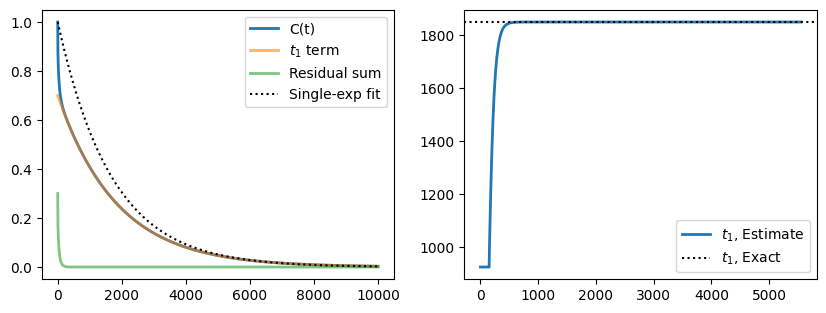

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from vac_metad.acf_toy import toy_model_acf
from vac_metad.math import derivative


def fit_single_exponential(t, y, tmax=None, unit_amplitude=False):
    """Linearized LSQ for y = A exp(-t/T). If unit_amplitude, A = 1 (fit through C(0)=1)."""
    t = np.asarray(t, float)
    y = np.asarray(y, float)
    m = y > 0
    if tmax is not None:
        m &= t <= tmax
    t, ly = t[m], np.log(y[m])
    if unit_amplitude:
        return 1.0, -np.sum(t * t) / np.sum(t * ly)  # slope = Σt·lnC / Σt²
    slope, intercept = np.polyfit(t, ly, 1)
    return np.exp(intercept), -1.0 / slope


def estimate_t1(frametime, ct, t1_guess=None, window=301):
    """Local relaxation time t1(τ) = -1 / (d ln C / dτ).

    Savitzky-Golay with polyorder=1, i.e. a sliding straight-line fit to ln C.
    The ACF is cut before its first non-positive value (ln undefined) and,
    if t1_guess is given, beyond 3*t1_guess (noise floor).

    Parameters
    ----------
    frametime : float
        Lag spacing of ct.
    ct : array, shape (num_lags,)
        Normalized ACF, ct[0] = 1.
    t1_guess : float, optional
        Rough t1; truncates the fit at 3*t1_guess.
    window : int
        Savitzky-Golay window in points (odd); ~10-30% of t1/frametime.

    Returns
    -------
    t1_local : array, shape (num_lags,)
        NaN beyond the cut. Read t_1 off the long-τ plateau.
    """
    ct = np.asarray(ct, float)
    t = frametime * np.arange(ct.size)
    n = np.argmax(ct <= 0) if (ct <= 0).any() else ct.size
    if t1_guess is not None:
        n = min(n, int(3 * t1_guess / frametime))
    w = min(window, n if n % 2 else n - 1)  # odd and <= n
    t1_local = np.full(ct.size, np.nan)
    if w >= 3:
        dlogC = derivative(
            t[:n], np.log(ct[:n]), method="savgol", window=w, polyorder=1
        )
        with np.errstate(divide="ignore"):
            t1_local[:n] = -1.0 / dlogC
    return t1_local


def plot_acf_components(ax, t, acf):
    ax.plot(t, acf.ct, label="C(t)", lw=2)
    ax.plot(t, acf.terms[0], label=r"$t_1$ term", lw=2, alpha=0.6)
    ax.plot(t, np.sum(acf.terms[1:], axis=0), label="Residual sum", lw=2, alpha=0.6)
    A, T = fit_single_exponential(t, acf.ct, unit_amplitude=True)
    ax.plot(t, A * np.exp(-t / T), ls=":", c="k", label="Single-exp fit")
    # ax.text(
    #     0.95,
    #     0.6,
    #     rf"$T = {T:.0f}$ ps, $A = {A:.2f}$",
    #     transform=ax.transAxes,
    #     ha="right",
    # )
    ax.legend()


def plot_t1_estimate(ax, t, t1, t1_exact):
    ax.plot(t, t1, label="$t_1$, Estimate", lw=2)
    ax.axhline(t1_exact, ls=":", c="k", label="$t_1$, Exact")
    ax.legend()


taus = np.arange(10_000)
acf = toy_model_acf(taus)
t1_local = estimate_t1(taus[1] - taus[0], acf.ct, t1_guess=1850, window=301)


fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
plot_acf_components(axs[0], taus, acf)
plot_t1_estimate(axs[1], taus, t1_local, acf.timescales[0])

In [ ]:
def fit_window(acf, t_min=None, t_max=None, k_sigma=3.0, t_min_frac=0.1):
    """Return (t_min, t_max) for the slow-tail fit.

    t_max : given, or the last lag before C_hat first drops below
            k_sigma * sigma (searching from lag 1), or the last lag if
            acf.sigma is None.
    t_min : given, or t_min_frac * t_max.
    """
    t, ct = acf.t, acf.ct
    if t_max is None:
        if acf.sigma is None:
            t_max = t[-1]
        else:
            low = np.flatnonzero(ct[1:] < k_sigma * acf.sigma[1:])
            t_max = t[low[0]] if low.size else t[-1]  # low[0]+1 is the first bad lag
    if t_min is None:
        t_min = t_min_frac * t_max
    if t_min >= t_max:
        raise ValueError(f"empty fit window: t_min={t_min} >= t_max={t_max}")
    return float(t_min), float(t_max)

In [ ]:
def fit_slow_exponential(
    acf,
    t_min=None,
    t_max=None,
    method="nonlinear",
    unit_amplitude=False,
    k_sigma=3.0,
    t_min_frac=0.1,
):
    """Fit C(t) ~ a_1 exp(-t / t_1) on [t_min, t_max].

    Parameters
    ----------
    acf : DataClass from acf_input
    t_min, t_max, k_sigma, t_min_frac : fit window, see fit_window
    method : 'nonlinear' (default) fits C itself, weighted by 1/sigma^2.
             'log' fits ln C by a straight line, weighted by C^2/sigma^2
             (the consistent weight for ln C).  Points with C <= 0 are
             dropped, which biases it upward in a noisy tail.
    unit_amplitude : force a_1 = 1 (the fit then goes through C(0) = 1)

    Returns
    -------
    DataClass with a1, t1, a1_err, t1_err, t_min, t_max, num_points.
    The errors assume independent noise per lag and are too small for real
    ACFs; use spread_over_draws for honest errors.
    """
    t_min, t_max = fit_window(acf, t_min, t_max, k_sigma, t_min_frac)
    sel = (acf.t >= t_min) & (acf.t <= t_max)
    t, c = acf.t[sel], acf.ct[sel]
    s = None if acf.sigma is None else acf.sigma[sel]

    # log-linear fit (also the starting guess for the nonlinear fit)
    pos = c > 0.0
    if pos.sum() < 2:
        raise ValueError("fewer than 2 positive C values in the fit window")
    s_log = None if s is None else s[pos] / c[pos]
    slope, icpt, cov = weighted_linear_fit(
        t[pos], np.log(c[pos]), s_log, through_origin=unit_amplitude
    )
    k, a = -slope, np.exp(icpt)
    k_err, a_err = np.sqrt(cov[0, 0]), a * np.sqrt(cov[1, 1])

    if method == "nonlinear":
        if unit_amplitude:
            f = lambda t, k: np.exp(-k * t)
            p0 = [k]
        else:
            f = lambda t, a, k: a * np.exp(-k * t)
            p0 = [a, k]
        p, pcov = curve_fit(f, t, c, p0=p0, sigma=s, absolute_sigma=s is not None)
        if unit_amplitude:
            k, k_err = p[0], np.sqrt(pcov[0, 0])
        else:
            (a, k), (a_err, k_err) = p, np.sqrt(np.diag(pcov))
    elif method != "log":
        raise ValueError("method must be 'nonlinear' or 'log'")

    return DataClass(
        a1=a,
        t1=1.0 / k,
        a1_err=a_err,
        t1_err=k_err / k**2,
        t_min=t_min,
        t_max=t_max,
        num_points=int(sel.sum()),
    )

In [ ]:
def acf_timescales(acf, c_window=5.0, **fit_kwargs):
    """The main timescales of an ACF.

    Parameters
    ----------
    acf : DataClass from acf_input
    c_window : Sokal window constant for tau_int_sokal
    fit_kwargs : passed to fit_slow_exponential (t_min, t_max, method, ...)

    Returns
    -------
    DataClass with
        tau_0 : one-frame chord -dt / ln C(dt); approximates -1/C'(0) only
            for dt much shorter than the fastest mode
        tau_int_sokal : Sokal-windowed integral of C (as in acf.py)
        tau_int_window : the Sokal window, in time units
        tau_int : tail-corrected integral of C (preferred)
        t1 : slowest timescale in u (= tau_exp), from the slow-tail fit
        a1 : slow-mode weight (fit intercept)
        a1_err, t1_err : single-fit errors (optimistic)
        purity : tau_int / t1, an upper bound on a1 (equal to it when the
            fast modes are negligibly short)
        t_min, t_max : slow-tail fit window
    """
    fit = fit_slow_exponential(acf, **fit_kwargs)
    tau_sokal, t_win = sokal_tau_int(acf, c_window)
    tau_int = tail_corrected_tau_int(acf, fit.a1, fit.t1, fit.t_max)
    c1 = acf.ct[1]
    tau_0 = -acf.frametime / np.log(c1) if 0.0 < c1 < 1.0 else np.nan
    return DataClass(
        tau_0=tau_0,
        tau_int_sokal=tau_sokal,
        tau_int_window=t_win,
        tau_int=tau_int,
        t1=fit.t1,
        a1=fit.a1,
        t1_err=fit.t1_err,
        a1_err=fit.a1_err,
        purity=tau_int / fit.t1,
        t_min=fit.t_min,
        t_max=fit.t_max,
    )

### A.2 Estimate of $a_1$

Estimates: t1 = 1850.000 ps, a1 = 0.7000


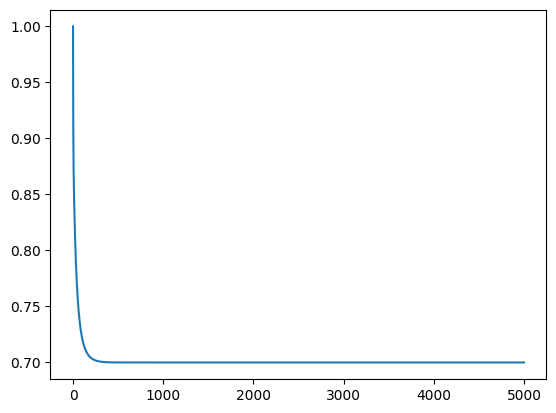

In [12]:
t1_est = np.mean(t1_local[1000:])
a1_local = np.exp(np.log(acf.ct) + taus / t1_est)
a1_est = np.mean(a1_local[1000:])
print(f"Estimates: t1 = {t1_est:.3f} ps, a1 = {a1_est:.4f}")
plt.plot(a1_local)

np.float64(1849.999978885504)